# 05 — EGFR Candidate Screening

## Objective

The best-performing machine learning model was used to prioritize compounds with predicted EGFR inhibitory activity. The Morgan fingerprint Random Forest was selected based on its performance during model evaluation and scaffold-based validation. Candidate compounds were represented using 2,048-bit Morgan fingerprints and ranked according to predicted pIC50. Highly ranked compounds were subsequently evaluated using physicochemical and drug-likeness criteria to identify candidates for molecular docking.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, Lipinski, Crippen
from sklearn.ensemble import RandomForestRegressor

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"

RESULTS_DIR.mkdir(exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_DATA_DIR)

Project root: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery
Processed data: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/data/processed


## Final Model Training

The Morgan fingerprint Random Forest was selected as the final predictive model because it provided the strongest overall performance among the evaluated approaches. After model evaluation was completed, the model was retrained using the full available EGFR bioactivity dataset to maximize the information available for subsequent candidate screening.

In [2]:
fingerprints = np.load(
    PROCESSED_DATA_DIR / "egfr_morgan_fingerprints.npz",
    allow_pickle=True
)

print(fingerprints.files)

['fingerprints', 'molecule_chembl_id', 'pIC50']


In [3]:
X_final = fingerprints["fingerprints"]
y_final = fingerprints["pIC50"]

print("Fingerprint matrix:", X_final.shape)
print("Target:", y_final.shape)

Fingerprint matrix: (10381, 2048)
Target: (10381,)


In [4]:
final_rf_model = RandomForestRegressor(
    n_estimators=500,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

final_rf_model.fit(X_final, y_final)

print("Final Morgan Random Forest trained.")
print("Training molecules:", len(y_final))
print("Fingerprint features:", X_final.shape[1])

Final Morgan Random Forest trained.
Training molecules: 10381
Fingerprint features: 2048


In [5]:
import joblib

MODEL_DIR = PROJECT_ROOT / "results" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "egfr_morgan_rf_final.joblib"

joblib.dump(final_rf_model, model_path)

print("Model saved to:")
print(model_path)

Model saved to:
/Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/models/egfr_morgan_rf_final.joblib


## External Compound Library

An external library of drug-like small molecules was used to identify potential EGFR inhibitor candidates not included in model training. Compounds were represented using the same 2,048-bit Morgan fingerprint representation used to train the final Random Forest model. Predicted pIC50 values were generated for each compound, allowing the library to be ranked according to predicted EGFR inhibitory activity. Highly ranked compounds were subsequently filtered using molecular properties and structural similarity before selection for molecular docking.

In [7]:
# Load the external ZINC lead-like compound library
zinc_df = pd.read_csv("../data/raw/zinc_lead_like_random.csv")

print("Dataset shape:", zinc_df.shape)
print("\nColumns:")
print(zinc_df.columns.tolist())

zinc_df.head()

Dataset shape: (10000, 3)

Columns:
['tranche', 'zincid', 'SMILES']


,tranche,zincid,SMILES
0,H23P120,ZINCni00000Uj92D,C=CCC(=O)N1C[C@H]2CN(C(=O)/C=C/[C@@H]3CCCN3C)C...
1,H25P020,ZINCp8000006CZgm,COC[C@@](C)(O)C(=O)N1CC(N(C)C(=O)Cc2coc(C(F)F)...
2,H25P200,ZINCpq00000m8N76,CCc1nc([C@@H](N[C@H]2CCCC[C@@H]2SC)c2nnnn2C2CC...
3,H22M100,ZINCm400000x6VDA,O=C(NC[C@@H](O)CO)[C@H]1[C@@H]2C[C@H]1CN2C(=O)...
4,H25P050,ZINCpb00000VWafu,C[C@H](C(=O)N(C)C1CN(C(=O)CCc2ccn(C)n2)C1)c1cc...


## External Library Preprocessing

The ZINC lead-like compound library was validated prior to molecular fingerprint generation. SMILES strings were converted into RDKit molecular objects, and compounds with invalid or missing molecular structures were removed. This ensured that only chemically interpretable compounds were included in the virtual screening workflow.

In [9]:
from rdkit import Chem

# Convert SMILES to RDKit molecules
zinc_df["mol"] = zinc_df["SMILES"].apply(Chem.MolFromSmiles)

# Check validity
valid_count = zinc_df["mol"].notna().sum()
invalid_count = zinc_df["mol"].isna().sum()

print("Total compounds:", len(zinc_df))
print("Valid compounds:", valid_count)
print("Invalid compounds:", invalid_count)

Total compounds: 10000
Valid compounds: 10000
Invalid compounds: 0


In [10]:
zinc_clean = zinc_df.dropna(subset=["mol"]).copy()
zinc_clean.reset_index(drop=True, inplace=True)

print("Compounds retained for screening:", len(zinc_clean))

Compounds retained for screening: 10000


In [12]:
# Canonicalize ZINC SMILES
zinc_clean["canonical_smiles"] = zinc_clean["mol"].apply(
    lambda mol: Chem.MolToSmiles(mol, canonical=True)
)

# Load the processed EGFR training dataset
training_df = pd.read_csv(
    "../data/processed/egfr_molecule_activity_with_smiles.csv"
)

print("Training dataset shape:", training_df.shape)
print("Training columns:", training_df.columns.tolist())

Training dataset shape: (10381, 8)
Training columns: ['molecule_chembl_id', 'median_ic50_nM', 'n_measurements', 'min_ic50_nM', 'max_ic50_nM', 'pIC50', 'canonical_smiles', 'valid_smiles']


In [13]:
training_df.columns.tolist()

['molecule_chembl_id',
 'median_ic50_nM',
 'n_measurements',
 'min_ic50_nM',
 'max_ic50_nM',
 'pIC50',
 'canonical_smiles',
 'valid_smiles']

In [14]:
# Canonicalize training-set SMILES
training_mols = training_df["canonical_smiles"].apply(Chem.MolFromSmiles)

training_df["canonical_smiles_standard"] = training_mols.apply(
    lambda mol: Chem.MolToSmiles(mol, canonical=True)
    if mol is not None else None
)

# Create set of structures used during model training
training_smiles = set(
    training_df["canonical_smiles_standard"].dropna()
)

# Identify overlap between ZINC and training data
zinc_clean["in_training_data"] = (
    zinc_clean["canonical_smiles"].isin(training_smiles)
)

print(
    "Compounds overlapping training data:",
    zinc_clean["in_training_data"].sum()
)

print(
    "Novel compounds:",
    (~zinc_clean["in_training_data"]).sum()
)

Compounds overlapping training data: 0
Novel compounds: 10000


In [15]:
zinc_screen = zinc_clean[
    ~zinc_clean["in_training_data"]
].copy()

zinc_screen.reset_index(drop=True, inplace=True)

print("Final screening library:", len(zinc_screen))

Final screening library: 10000


## Morgan Fingerprint Generation for Candidate Screening

Morgan molecular fingerprints were generated for each compound in the external ZINC library using the same 2,048-bit representation used to train the Random Forest model. Maintaining the same molecular representation allows the trained model to predict EGFR inhibitory activity for previously unseen compounds.

In [16]:
from rdkit.Chem import AllChem
from rdkit import DataStructs
import numpy as np

# Morgan fingerprint generator
morgan_generator = AllChem.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

def mol_to_fingerprint(mol):
    fp = morgan_generator.GetFingerprint(mol)

    arr = np.zeros((2048,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    return arr

# Generate fingerprints for all screening compounds
zinc_fingerprints = np.array(
    zinc_screen["mol"].apply(mol_to_fingerprint).tolist()
)

print("Number of compounds:", zinc_fingerprints.shape[0])
print("Fingerprint features:", zinc_fingerprints.shape[1])

Number of compounds: 10000
Fingerprint features: 2048


In [17]:
import joblib

model_path = "../results/models/egfr_morgan_rf_final.joblib"

final_rf_model = joblib.load(model_path)

print("Final Random Forest model loaded.")

Final Random Forest model loaded.


In [18]:
zinc_screen["predicted_pIC50"] = final_rf_model.predict(
    zinc_fingerprints
)

print("Predictions complete.")

zinc_screen[
    ["zincid", "SMILES", "predicted_pIC50"]
].head()

Predictions complete.


,zincid,SMILES,predicted_pIC50
0,ZINCni00000Uj92D,C=CCC(=O)N1C[C@H]2CN(C(=O)/C=C/[C@@H]3CCCN3C)C...,5.793191
1,ZINCp8000006CZgm,COC[C@@](C)(O)C(=O)N1CC(N(C)C(=O)Cc2coc(C(F)F)...,6.321810
2,ZINCpq00000m8N76,CCc1nc([C@@H](N[C@H]2CCCC[C@@H]2SC)c2nnnn2C2CC...,6.344294
3,ZINCm400000x6VDA,O=C(NC[C@@H](O)CO)[C@H]1[C@@H]2C[C@H]1CN2C(=O)...,5.392904
4,ZINCpb00000VWafu,C[C@H](C(=O)N(C)C1CN(C(=O)CCc2ccn(C)n2)C1)c1cc...,5.184446


In [19]:
zinc_ranked = zinc_screen.sort_values(
    "predicted_pIC50",
    ascending=False
).reset_index(drop=True)

zinc_ranked["rank"] = np.arange(1, len(zinc_ranked) + 1)

zinc_ranked[
    ["rank", "zincid", "predicted_pIC50", "SMILES"]
].head(20)

,rank,zincid,predicted_pIC50,SMILES
0,1,ZINCow00000g35fQ,8.311889,CSCCNC(=O)C[C@H]1CCN(c2nc(C)nc3ccccc23)C1
1,2,ZINCpr00000m8N6T,8.200690,CCc1nc([C@H](NCC(C)(C)[C@H](C)O)c2nnnn2CCSC)cs1
2,3,ZINCne00000UlZfO,7.443468,C[C@@H](O)[C@H]1CCN1C(=O)[C@H](CN=[N+]=[N-])NC...
3,4,ZINCn500000UlZfQ,7.377480,C[C@@H](O)[C@H]1CCN1C(=O)[C@H](CN=[N+]=[N-])NC...
4,5,ZINCkl00001bOdn6,7.371151,CC[C@H](CCO)CN=c1nc(C)nc(NC2CSC2)[nH]1
5,6,ZINCnc00000UlZfA,7.369428,C[C@H](O)[C@H]1CCN1C(=O)[C@@H](C)NC(=O)c1ccc2c...
6,7,ZINCp8000006CY2l,7.360322,COC[C@@H](OC)C(=O)NCC[C@H]1CCCCN1c1nc(C)nc(=N)...
7,8,ZINCn700000UlZfR,7.352340,C[C@H](O)[C@H]1CCN1C(=O)[C@H](CN=[N+]=[N-])NC(...
8,9,ZINCn400000UlZfP,7.343700,C[C@H](O)[C@H]1CCN1C(=O)[C@H](CN=[N+]=[N-])NC(...
9,10,ZINClp00001bOdn7,7.335973,CC[C@H](CCO)CN=c1nc(C)nc(N[C@@H]2CCSC2)[nH]1


In [20]:
output_path = "../results/zinc_egfr_screening_predictions.csv"

zinc_ranked[
    ["rank", "zincid", "tranche", "SMILES", "predicted_pIC50"]
].to_csv(output_path, index=False)

print("Screening results saved to:")
print(output_path)

Screening results saved to:
../results/zinc_egfr_screening_predictions.csv


## Candidate Filtering and Drug-Likeness Assessment

Compounds with the highest predicted EGFR inhibitory activity were further evaluated using physicochemical properties relevant to small-molecule drug development. Molecular weight, lipophilicity, hydrogen-bond donors and acceptors, topological polar surface area, and rotatable bonds were calculated using RDKit. These properties were used to identify high-ranking compounds with suitable drug-like characteristics for subsequent molecular docking.

In [21]:
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

# Keep top 100 predicted compounds for further evaluation
top_candidates = zinc_ranked.head(100).copy()

def calculate_properties(mol):
    return pd.Series({
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "RotatableBonds": Lipinski.NumRotatableBonds(mol)
    })

properties = top_candidates["mol"].apply(calculate_properties)

top_candidates = pd.concat(
    [top_candidates.reset_index(drop=True),
     properties.reset_index(drop=True)],
    axis=1
)

top_candidates[
    ["rank", "zincid", "predicted_pIC50",
     "MolWt", "LogP", "HBD", "HBA", "TPSA", "RotatableBonds"]
].head(20)

,rank,zincid,predicted_pIC50,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds
0,1,ZINCow00000g35fQ,8.311889,344.484,2.63382,1.0,5.0,58.12,6.0
1,2,ZINCpr00000m8N6T,8.200690,384.575,2.14100,2.0,8.0,88.75,10.0
2,3,ZINCne00000UlZfO,7.443468,321.381,0.81270,2.0,4.0,118.40,5.0
3,4,ZINCn500000UlZfQ,7.377480,326.313,-0.57160,2.0,6.0,161.54,7.0
4,5,ZINCkl00001bOdn6,7.371151,297.428,0.94972,3.0,6.0,86.19,7.0
5,6,ZINCnc00000UlZfA,7.369428,316.361,0.66290,3.0,4.0,98.32,4.0
6,7,ZINCp8000006CY2l,7.360322,352.439,0.11919,3.0,7.0,116.22,8.0
7,8,ZINCn700000UlZfR,7.352340,325.369,0.18820,2.0,5.0,127.63,6.0
8,9,ZINCn400000UlZfP,7.343700,324.341,-1.11540,3.0,5.0,161.49,7.0
9,10,ZINClp00001bOdn7,7.335973,311.455,1.33982,3.0,6.0,86.19,7.0


In [22]:
top_candidates["lipinski_pass"] = (
    (top_candidates["MolWt"] <= 500) &
    (top_candidates["LogP"] <= 5) &
    (top_candidates["HBD"] <= 5) &
    (top_candidates["HBA"] <= 10)
)

print(
    "Top 100 passing Lipinski criteria:",
    top_candidates["lipinski_pass"].sum()
)

top_candidates[
    ["rank", "zincid", "predicted_pIC50",
     "MolWt", "LogP", "HBD", "HBA",
     "TPSA", "RotatableBonds", "lipinski_pass"]
].head(20)

Top 100 passing Lipinski criteria: 99


,rank,zincid,predicted_pIC50,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,lipinski_pass
0,1,ZINCow00000g35fQ,8.311889,344.484,2.63382,1.0,5.0,58.12,6.0,True
1,2,ZINCpr00000m8N6T,8.200690,384.575,2.14100,2.0,8.0,88.75,10.0,True
2,3,ZINCne00000UlZfO,7.443468,321.381,0.81270,2.0,4.0,118.40,5.0,True
3,4,ZINCn500000UlZfQ,7.377480,326.313,-0.57160,2.0,6.0,161.54,7.0,True
4,5,ZINCkl00001bOdn6,7.371151,297.428,0.94972,3.0,6.0,86.19,7.0,True
5,6,ZINCnc00000UlZfA,7.369428,316.361,0.66290,3.0,4.0,98.32,4.0,True
6,7,ZINCp8000006CY2l,7.360322,352.439,0.11919,3.0,7.0,116.22,8.0,True
7,8,ZINCn700000UlZfR,7.352340,325.369,0.18820,2.0,5.0,127.63,6.0,True
8,9,ZINCn400000UlZfP,7.343700,324.341,-1.11540,3.0,5.0,161.49,7.0,True
9,10,ZINClp00001bOdn7,7.335973,311.455,1.33982,3.0,6.0,86.19,7.0,True


## Chemical Similarity and Applicability Domain

To assess whether highly ranked ZINC compounds occupied chemical space represented in the EGFR training dataset, Morgan fingerprint similarity was calculated between each candidate and compounds used for model training. Maximum Tanimoto similarity to the training set was recorded for each candidate. This analysis provides an estimate of the model's applicability domain and helps distinguish predictions supported by structurally related training compounds from extrapolations to unfamiliar chemical structures.

In [23]:
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator

# Use the same fingerprint settings used for model training
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

# Convert training SMILES to RDKit molecules
training_mols = [
    Chem.MolFromSmiles(smiles)
    for smiles in training_df["canonical_smiles"]
]

# Remove any invalid molecules
training_mols = [
    mol for mol in training_mols
    if mol is not None
]

# Generate Morgan fingerprints
training_fps = [
    morgan_generator.GetFingerprint(mol)
    for mol in training_mols
]

print("Training fingerprints:", len(training_fps))

Training fingerprints: 10381


In [24]:
def max_training_similarity(mol):
    fp = morgan_generator.GetFingerprint(mol)

    similarities = DataStructs.BulkTanimotoSimilarity(
        fp,
        training_fps
    )

    return max(similarities)


top_candidates["max_training_similarity"] = (
    top_candidates["mol"].apply(max_training_similarity)
)

In [25]:
top_candidates[
    [
        "rank",
        "zincid",
        "predicted_pIC50",
        "max_training_similarity",
        "MolWt",
        "LogP",
        "lipinski_pass"
    ]
].head(20)

,rank,zincid,predicted_pIC50,max_training_similarity,MolWt,LogP,lipinski_pass
0,1,ZINCow00000g35fQ,8.311889,0.324324,344.484,2.63382,True
1,2,ZINCpr00000m8N6T,8.200690,0.186275,384.575,2.14100,True
2,3,ZINCne00000UlZfO,7.443468,0.166667,321.381,0.81270,True
3,4,ZINCn500000UlZfQ,7.377480,0.157303,326.313,-0.57160,True
4,5,ZINCkl00001bOdn6,7.371151,0.180723,297.428,0.94972,True
5,6,ZINCnc00000UlZfA,7.369428,0.270588,316.361,0.66290,True
6,7,ZINCp8000006CY2l,7.360322,0.215054,352.439,0.11919,True
7,8,ZINCn700000UlZfR,7.352340,0.157303,325.369,0.18820,True
8,9,ZINCn400000UlZfP,7.343700,0.166667,324.341,-1.11540,True
9,10,ZINClp00001bOdn7,7.335973,0.174419,311.455,1.33982,True


In [26]:
top_candidates["max_training_similarity"].describe()

count    100.000000
mean       0.226184
std        0.040896
min        0.156863
25%        0.198004
50%        0.224921
75%        0.250000
max        0.396552
Name: max_training_similarity, dtype: float64

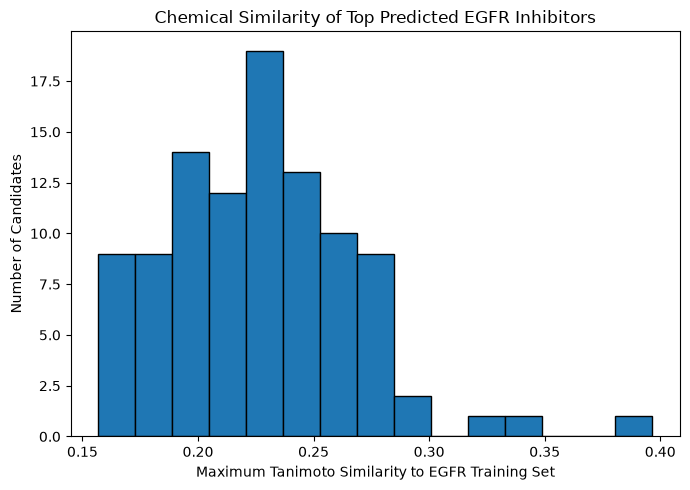

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.hist(
    top_candidates["max_training_similarity"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("Maximum Tanimoto Similarity to EGFR Training Set")
plt.ylabel("Number of Candidates")
plt.title("Chemical Similarity of Top Predicted EGFR Inhibitors")

plt.tight_layout()
plt.show()

## Predicted Activity and Training-Set Similarity

Because the screened ZINC compounds showed relatively low structural similarity to the EGFR training dataset, predicted activity was evaluated together with maximum Tanimoto similarity. This comparison was used to identify candidates that balanced high predicted EGFR inhibitory activity with greater representation within the model's learned chemical space. Similarity was used as a confidence-supporting criterion rather than a strict exclusion threshold.

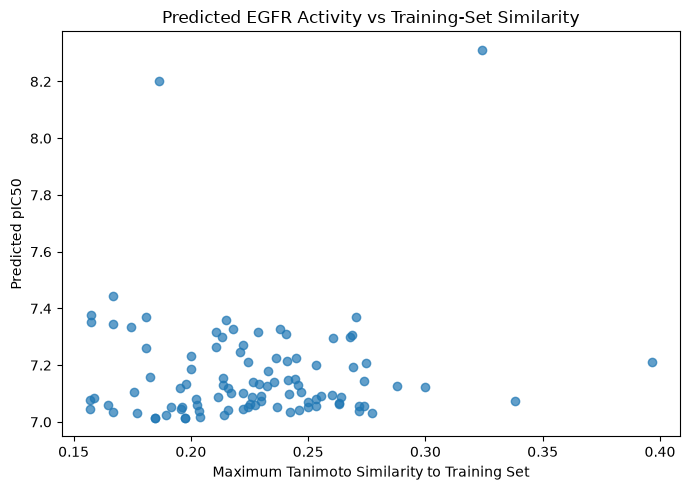

In [28]:
plt.figure(figsize=(7, 5))

plt.scatter(
    top_candidates["max_training_similarity"],
    top_candidates["predicted_pIC50"],
    alpha=0.7
)

plt.xlabel("Maximum Tanimoto Similarity to Training Set")
plt.ylabel("Predicted pIC50")
plt.title("Predicted EGFR Activity vs Training-Set Similarity")

plt.tight_layout()
plt.show()

In [29]:
top_candidates[
    [
        "rank",
        "zincid",
        "predicted_pIC50",
        "max_training_similarity",
        "MolWt",
        "LogP",
        "lipinski_pass"
    ]
].sort_values(
    ["predicted_pIC50", "max_training_similarity"],
    ascending=False
).head(30)

,rank,zincid,predicted_pIC50,max_training_similarity,MolWt,LogP,lipinski_pass
0,1,ZINCow00000g35fQ,8.311889,0.324324,344.484,2.63382,True
1,2,ZINCpr00000m8N6T,8.200690,0.186275,384.575,2.14100,True
2,3,ZINCne00000UlZfO,7.443468,0.166667,321.381,0.81270,True
3,4,ZINCn500000UlZfQ,7.377480,0.157303,326.313,-0.57160,True
4,5,ZINCkl00001bOdn6,7.371151,0.180723,297.428,0.94972,True
5,6,ZINCnc00000UlZfA,7.369428,0.270588,316.361,0.66290,True
6,7,ZINCp8000006CY2l,7.360322,0.215054,352.439,0.11919,True
7,8,ZINCn700000UlZfR,7.352340,0.157303,325.369,0.18820,True
8,9,ZINCn400000UlZfP,7.343700,0.166667,324.341,-1.11540,True
9,10,ZINClp00001bOdn7,7.335973,0.174419,311.455,1.33982,True


In [30]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

top_candidates[
    ["activity_scaled", "similarity_scaled"]
] = scaler.fit_transform(
    top_candidates[
        ["predicted_pIC50", "max_training_similarity"]
    ]
)

# Give predicted activity more weight than similarity
top_candidates["combined_score"] = (
    0.70 * top_candidates["activity_scaled"] +
    0.30 * top_candidates["similarity_scaled"]
)

ranked_candidates = (
    top_candidates[
        top_candidates["lipinski_pass"]
    ]
    .sort_values(
        "combined_score",
        ascending=False
    )
    .copy()
)

ranked_candidates[
    [
        "zincid",
        "predicted_pIC50",
        "max_training_similarity",
        "combined_score",
        "MolWt",
        "LogP"
    ]
].head(20)

,zincid,predicted_pIC50,max_training_similarity,combined_score,MolWt,LogP
0,ZINCow00000g35fQ,8.311889,0.324324,0.909599,344.484,2.63382
1,ZINCpr00000m8N6T,8.200690,0.186275,0.676857,384.575,2.14100
28,ZINCnG00000g0nB3,7.210323,0.396552,0.406070,327.344,3.66970
5,ZINCnc00000UlZfA,7.369428,0.270588,0.334196,316.361,0.66290
15,ZINCpc000015MNGn,7.307967,0.268817,0.298841,350.423,0.60992
17,ZINCmF000009qF0V,7.298016,0.268041,0.292505,298.386,3.54830
18,ZINCpJ00000sUCKz,7.294344,0.260417,0.280982,360.889,3.94562
10,ZINCok00000rV1M6,7.329053,0.238095,0.271758,331.468,1.41804
14,ZINCou00000pgX9h,7.311666,0.240385,0.265249,395.257,2.43970
6,ZINCp8000006CY2l,7.360322,0.215054,0.259778,352.439,0.11919


## Structural Diversity of Final Candidates

Highly ranked compounds may contain closely related chemical structures, which could result in redundant candidates being selected for molecular docking. To increase the chemical diversity of the final candidate set, pairwise Tanimoto similarity was evaluated among highly ranked compounds using Morgan fingerprints. Candidates were selected sequentially according to their combined activity and training-set similarity score while excluding compounds that were highly similar to compounds already selected. This produced a structurally diverse subset of predicted EGFR inhibitors for subsequent molecular docking.

In [31]:
# Generate fingerprints for ranked candidates
ranked_candidates["fingerprint"] = ranked_candidates["mol"].apply(
    lambda mol: morgan_generator.GetFingerprint(mol)
)

print("Ranked candidates:", len(ranked_candidates))

Ranked candidates: 99


In [32]:
candidate_pool = ranked_candidates.head(50).copy()

selected_indices = []
selected_fps = []

SIMILARITY_THRESHOLD = 0.70
N_FINAL = 10

for idx, row in candidate_pool.iterrows():

    fp = row["fingerprint"]

    # Automatically select first/highest-ranked compound
    if len(selected_fps) == 0:
        selected_indices.append(idx)
        selected_fps.append(fp)
        continue

    similarities = DataStructs.BulkTanimotoSimilarity(
        fp,
        selected_fps
    )

    # Keep compound only if it is sufficiently different
    # from all compounds already selected
    if max(similarities) < SIMILARITY_THRESHOLD:
        selected_indices.append(idx)
        selected_fps.append(fp)

    if len(selected_indices) == N_FINAL:
        break

final_candidates = ranked_candidates.loc[selected_indices].copy()

print("Final candidates selected:", len(final_candidates))

Final candidates selected: 10


In [33]:
final_candidates[
    [
        "zincid",
        "predicted_pIC50",
        "max_training_similarity",
        "combined_score",
        "MolWt",
        "LogP",
        "HBD",
        "HBA",
        "TPSA"
    ]
].reset_index(drop=True)

,zincid,predicted_pIC50,max_training_similarity,combined_score,MolWt,LogP,HBD,HBA,TPSA
0,ZINCow00000g35fQ,8.311889,0.324324,0.909599,344.484,2.63382,1.0,5.0,58.12
1,ZINCpr00000m8N6T,8.200690,0.186275,0.676857,384.575,2.14100,2.0,8.0,88.75
2,ZINCnG00000g0nB3,7.210323,0.396552,0.406070,327.344,3.66970,3.0,6.0,86.72
3,ZINCnc00000UlZfA,7.369428,0.270588,0.334196,316.361,0.66290,3.0,4.0,98.32
4,ZINCpc000015MNGn,7.307967,0.268817,0.298841,350.423,0.60992,2.0,7.0,99.69
5,ZINCmF000009qF0V,7.298016,0.268041,0.292505,298.386,3.54830,0.0,3.0,44.12
6,ZINCpJ00000sUCKz,7.294344,0.260417,0.280982,360.889,3.94562,0.0,3.0,51.02
7,ZINCok00000rV1M6,7.329053,0.238095,0.271758,331.468,1.41804,1.0,6.0,62.11
8,ZINCou00000pgX9h,7.311666,0.240385,0.265249,395.257,2.43970,0.0,5.0,76.80
9,ZINCp8000006CY2l,7.360322,0.215054,0.259778,352.439,0.11919,3.0,7.0,116.22


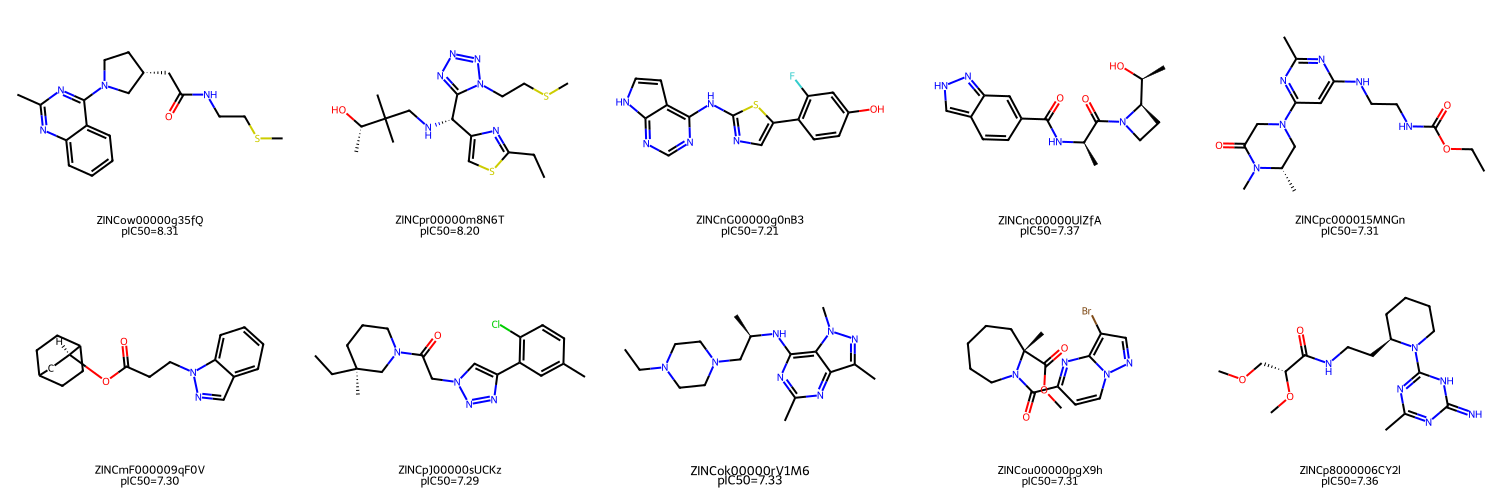

In [34]:
from rdkit.Chem import Draw

mols = final_candidates["mol"].tolist()

labels = [
    f"{row.zincid}\npIC50={row.predicted_pIC50:.2f}"
    for _, row in final_candidates.iterrows()
]

img = Draw.MolsToGridImage(
    mols,
    molsPerRow=5,
    subImgSize=(300, 250),
    legends=labels
)

img

In [35]:
FINAL_DIR = PROJECT_ROOT / "results" / "candidates"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

final_output = final_candidates.drop(
    columns=["mol", "fingerprint"],
    errors="ignore"
)

final_output.to_csv(
    FINAL_DIR / "final_egfr_candidates.csv",
    index=False
)

print("Saved:")
print(FINAL_DIR / "final_egfr_candidates.csv")

Saved:
/Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/candidates/final_egfr_candidates.csv
